# LAB 4F – NEURAL TTS PRETRAINED, CHỈ SỬ DỤNG MODEL ĐÃ CÓ TRÊN MÁY

**Yêu cầu mục 4.6:** cùng 3 câu test, WAV và mel-spectrogram, latency, chạy local/offline.

**Không tạo môi trường mới, không tải mô hình và không sinh audio giả.** SDK `vieneu 3.8.3` chạy từ Conda `vieneu-tts` cài sẵn; file backend `neural_tts_backend_offline.py` tắt Hugging Face online **trước khi import SDK**. Model weights chỉ được xác nhận là đã có khi chạy inference thành công **sau khi ngắt mạng**. Các bước A–E không bị ghi đè.


## 0. Chuẩn bị

Đặt notebook này, `neural_tts_backend_offline.py`, `lab04_f_tests.json` tại thư mục `Lab04_TTS/` cùng cấp `lab4_data/units/`. Giữ nguyên Kernel Python của Lab 4 A–E. Trong Terminal xem `conda env list`, kiểm tra SDK bằng `conda run -n vieneu-tts python -c "from vieneu import Vieneu; print('SDK OK')"`. **Không chạy pip install trong môi trường VieNeu nếu đã có SDK**.

Trước lúc chạy phần inference, **ngắt Wi-Fi hoặc ngắt kết nối mạng**. Mã nguồn khóa Hugging Face Hub và không chứa tùy chọn download; dùng SDK đã cài và cache hiện có. Nếu báo thiếu trọng số, dừng ở đây; không giả lập kết quả.


In [3]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from math import gcd
from IPython.display import display, Audio

ROOT=Path.cwd().resolve()
UNIT_DIR=ROOT/'lab4_data'/'units'
OUT_DIR=ROOT/'audio_output'
FIG_DIR=ROOT/'figures'
EVAL_DIR=ROOT/'evaluation'
for d in (OUT_DIR,FIG_DIR,EVAL_DIR): d.mkdir(parents=True,exist_ok=True)

BACKEND = ROOT / 'neural_tts_backend_offline.py'
TESTS_PATH = ROOT / 'lab04_f_tests.json'
assert BACKEND.is_file(), f'Thiếu: {BACKEND}'
assert TESTS_PATH.is_file(), f'Thiếu: {TESTS_PATH}'
assert UNIT_DIR.is_dir(), f'Thiếu folder units: {UNIT_DIR}'
print('ROOT:',ROOT)
print('Kernel:',sys.executable)

ROOT: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien
Kernel: c:\Users\admin\AppData\Local\Programs\Python\Python310\python.exe


## 1. Cấu hình kết quả

`BACKEND_MODE='auto'` cho SDK tự chọn backend dựa vào môi trường và weights hiện có. Nếu máy đã lưu ONNX/CPU mà SDK lại chọn GPU thì đặt `'onnx'`; nếu đã lưu weights GPU/PyTorch thì chọn `'torch'`. Đổi backend có thể yêu cầu weights khác; không tự động tải. Để `VOICE=''` dùng giọng mặc định, tránh phụ thuộc preset ngoài cache. **Không có biến cho phép tải model.**

In [4]:
RUNNER = 'conda'               # môi trường notebook A–E gọi SDK bằng Conda
CONDA_ENV_NAME = 'vieneu-tts'  # đã cài sẵn trước đó
BACKEND_MODE = 'auto'          # 'auto', 'onnx', hoặc 'torch' (chỉ weights local)
VOICE = ''                     # giữ mặc định; hoặc preset giọng đã có
CROSSFADE_MS = 15

from neural_tts_backend_offline import read_tests
TESTS = read_tests(TESTS_PATH)
display(pd.DataFrame([{'id':r['id'],'input_text':r['original_text'],
                       'spoken_text':r['spoken_text'], 'n_words':len(r['tokens'])} for r in TESTS]))

,id,input_text,spoken_text,n_words
0,test01,Mời khách hàng số 23 đến quầy 5.,Mời khách hàng số hai ba đến quầy năm.,9
1,test02,Mời khách hàng số 07 đến quầy 3.,Mời khách hàng số không bảy đến quầy ba.,9
2,test03,Mời khách hàng số 18 đến quầy 2.,Mời khách hàng số một tám đến quầy hai.,9


## 2. Kiểm tra dữ liệu và tạo bản ghép đối chứng cho cả ba câu

Sử dụng candidate `_01` và cross-fade **15 ms**, không dùng weights model hoặc HMM. Đây là bản ghép **đối chứng**, không phải kết quả neural. Bản gốc `raw_concat.wav` và `best_concat.wav` từ bước B/C được giữ nguyên. Không dùng cùng bản ghi `_01` hai lần để gọi là hai candidate khác nhau.

In [5]:
STEMS = {'mời':'moi','khách':'khach','hàng':'hang','số':'so',
 'không':'khong','một':'mot','hai':'hai','ba':'ba','bốn':'bon','năm':'nam',
 'sáu':'sau','bảy':'bay','tám':'tam','chín':'chin','đến':'den','quầy':'quay'}
SR=16000

def get_unit(w):
    p=UNIT_DIR/f'{STEMS[w]}_01.wav'
    if not p.is_file(): raise FileNotFoundError('Thiếu word unit: '+str(p))
    x,sr=sf.read(p,dtype='float32')
    if sr!=SR or x.ndim!=1: raise ValueError(f'{p}: cần WAV mono 16k, nhận {sr}, shape {x.shape}')
    return x

def crossfade(a,b,n):
    n=min(int(n),len(a),len(b))
    if n<=0: return np.concatenate((a,b))
    # ramp avoids hard sample cut, only subjective listening establishes quality
    alpha=np.linspace(0,1,n,endpoint=True,dtype=np.float32)
    return np.concatenate((a[:-n],(1-alpha)*a[-n:]+alpha*b[:n],b[n:]))

def concat_fixed01(tokens,ms=15):
    units=[get_unit(w) for w in tokens]
    out=units[0]
    for nxt in units[1:]: out=crossfade(out,nxt,int(round(ms*SR/1000)))
    return np.clip(out,-.999,.999)

concat_rows=[]
for t in TESTS:
    y=concat_fixed01(t['tokens'],CROSSFADE_MS)
    path=OUT_DIR/f'f_concat_{t["id"]}.wav'
    sf.write(path,y,SR,subtype='PCM_16')
    concat_rows.append({'id':t['id'],'concat_audio_path':str(path),
                        'concat_duration_s':len(y)/SR,'concat_rms':float(np.sqrt(np.mean(y.astype('float64')**2)))})
CONCAT_DF=pd.DataFrame(concat_rows)
display(CONCAT_DF)
print('Đã lưu 3 file concat đối chứng; CHƯA sinh neural audio.')

,id,concat_audio_path,concat_duration_s,concat_rms
0,test01,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...,4.880,0.080900
1,test02,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...,5.005,0.080874
2,test03,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...,5.005,0.080867


Đã lưu 3 file concat đối chứng; CHƯA sinh neural audio.


## 3. Kiểm tra văn bản trước khi gọi model (không tải model)

In [6]:
cmd=[sys.executable,str(BACKEND),'--input',str(TESTS_PATH),'--dry-run']
check=subprocess.run(cmd,cwd=str(ROOT),capture_output=True,text=True,encoding='utf-8',errors='replace')
print(check.stdout)
if check.returncode: raise RuntimeError(check.stderr[-2000:])

SDK local executable: c:\Users\admin\AppData\Local\Programs\Python\Python310\python.exe
Offline flags: {'HF_HUB_OFFLINE': '1', 'TRANSFORMERS_OFFLINE': '1', 'HF_DATASETS_OFFLINE': '1'}
test01: Mời khách hàng số hai ba đến quầy năm.
test02: Mời khách hàng số không bảy đến quầy ba.
test03: Mời khách hàng số một tám đến quầy hai.
DRY RUN OK – không tải model, không tạo WAV



## 4. Chạy inference thật, hoàn toàn offline

Chỉ chạy khi máy đã **ngắt Internet**. `HF_HUB_OFFLINE=1` và các offline flags cũng được đặt ở backend trước khi import SDK. Thời gian `latency_s` chỉ tính lời gọi inference; `input_to_audio_save_s` tính cả lưu file; `model_load_s` được báo riêng. Nếu model chưa có thì báo lỗi; **không tải tự động hoặc tạo WAV giả**.

In [7]:
import os
if RUNNER=='conda':
    cmd=['conda','run','--no-capture-output','-n',CONDA_ENV_NAME,
         'python',str(BACKEND)]
elif RUNNER=='current':
    cmd=[sys.executable,str(BACKEND)]
else:
    raise ValueError('RUNNER phải là conda hoặc current')
cmd += ['--input',str(TESTS_PATH),'--output',str(OUT_DIR),'--backend',BACKEND_MODE]
if VOICE: cmd += ['--voice',VOICE]
print('Đang dùng mô hình pretrained LOCAL: VieNeu v3 Turbo; tải model bị vô hiệu hóa.')
env=os.environ.copy()
env.update(HF_HUB_OFFLINE='1',TRANSFORMERS_OFFLINE='1',HF_DATASETS_OFFLINE='1',HF_HUB_DISABLE_TELEMETRY='1')
try:
    result=subprocess.run(cmd,cwd=str(ROOT),capture_output=True,text=True,
                          encoding='utf-8',errors='replace',env=env)
except FileNotFoundError as exc:
    raise RuntimeError('Không tìm thấy Conda. Mở VS Code từ Anaconda Prompt hoặc chọn RUNNER=current khi đang ở vieneu-tts.') from exc
print((result.stdout or '')[-6000:])
if result.returncode:
    print((result.stderr or '')[-8000:])
    raise RuntimeError('VieNeu offline không chạy thành công. Có thể weights thiếu/không đúng backend. Không tạo WAV giả hoặc tải trọng số khác.')
assert (EVAL_DIR/'f_neural_metrics.json').exists()
print('Đã có WAV được tạo từ SDK local; hãy xác nhận máy ngắt mạng trong lúc chạy để làm minh chứng offline.')

Đang dùng mô hình pretrained LOCAL: VieNeu v3 Turbo; tải model bị vô hiệu hóa.
SDK local executable: C:\Users\admin\anaconda3\envs\vieneu-tts\python.exe
Offline flags: {'HF_HUB_OFFLINE': '1', 'TRANSFORMERS_OFFLINE': '1', 'HF_DATASETS_OFFLINE': '1'}
test01: Mời khách hàng số hai ba đến quầy năm.
test02: Mời khách hàng số không bảy đến quầy ba.
test03: Mời khách hàng số một tám đến quầy hai.
Khởi tạo model CÓ SẴN: mode=v3turbo, backend=auto
Generating 1/3 test01...
Saved C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\neural_test01.wav | 2.08s audio | infer 1.92s | RTF 0.921
Generating 2/3 test02...
Saved C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\neural_test02.wav | 2.00s audio | infer 1.56s | RTF 0.780
Generating 3/3 test03...
Saved C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\neural_test03.wav | 2.00s audio | infer 1.54s | RTF 0.770
3 WAV generated locally, no download option exposed

Đã có WAV được tạo từ SDK local; hãy xác nhận máy ngắt mạ

## 5. Kiểm tra đầu ra, tạo WAV 16 kHz và bảng latency

Tần số gốc của VieNeu v3 Turbo thông thường là 48 kHz; kiểm tra tần số **thực tế từ file** thay vì giả định. Tạo thêm bản resample cho đối chiếu, không ghi đè file gốc.

In [8]:
metrics=json.loads((EVAL_DIR/'f_neural_metrics.json').read_text(encoding='utf-8'))
assert len(metrics)==len(TESTS) and all(m.get('is_mock') is False for m in metrics)
comparison=[]
for m in metrics:
    native=Path(m['native_audio_path'])
    assert native.exists(), f'Thiếu WAV neural: {native}'
    y,sr=sf.read(native,dtype='float32')
    if y.ndim>1: y=y.mean(axis=1)
    if sr!=SR:
        z=resample_poly(y,SR//gcd(SR,sr),sr//gcd(SR,sr)).astype('float32')
    else: z=y.copy()
    wav16=OUT_DIR/f'neural_{m["id"]}_16k.wav'
    sf.write(wav16,np.clip(z,-.999,.999),SR,subtype='PCM_16')
    comparison.append({'id':m['id'],'input_text':m['original_text'],
       'spoken_text':m['spoken_text'],'audio_path_native':str(native),
       'native_sr':sr,'audio_path_16k':str(wav16),
       'neural_duration_s':round(len(z)/SR,4),
       'latency_s':round(float(m['latency_s']),4),
       'RTF':round(float(m['rtf']),4),
       'model_load_s':round(float(m['model_load_s']),4),
       'voice':m['voice'],'sdk_version':m['sdk_version']})
METRICS_DF=pd.DataFrame(comparison).merge(CONCAT_DF,on='id',how='inner')
METRICS_DF.to_csv(EVAL_DIR/'f_neural_latency_comparison.csv',index=False,encoding='utf-8-sig')
display(METRICS_DF[['id','spoken_text','native_sr','neural_duration_s',
                    'concat_duration_s','latency_s','RTF','voice']])

,id,spoken_text,native_sr,neural_duration_s,concat_duration_s,latency_s,RTF,voice
0,test01,Mời khách hàng số hai ba đến quầy năm.,48000,2.08,4.880,1.9163,0.9213,SDK default
1,test02,Mời khách hàng số không bảy đến quầy ba.,48000,2.00,5.005,1.5601,0.7801,SDK default
2,test03,Mời khách hàng số một tám đến quầy hai.,48000,2.00,5.005,1.5408,0.7704,SDK default


## 6. Biểu đồ mel-spectrogram từ WAV neural đã sinh

**Phân biệt:** Đây là log-mel được **tính lại từ audio đầu ra**, không phải mel tensor nội bộ do SDK trả về. Nếu SDK không xuất mel nội bộ thì không được gọi đây là “model-produced mel”.

c:\Users\admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


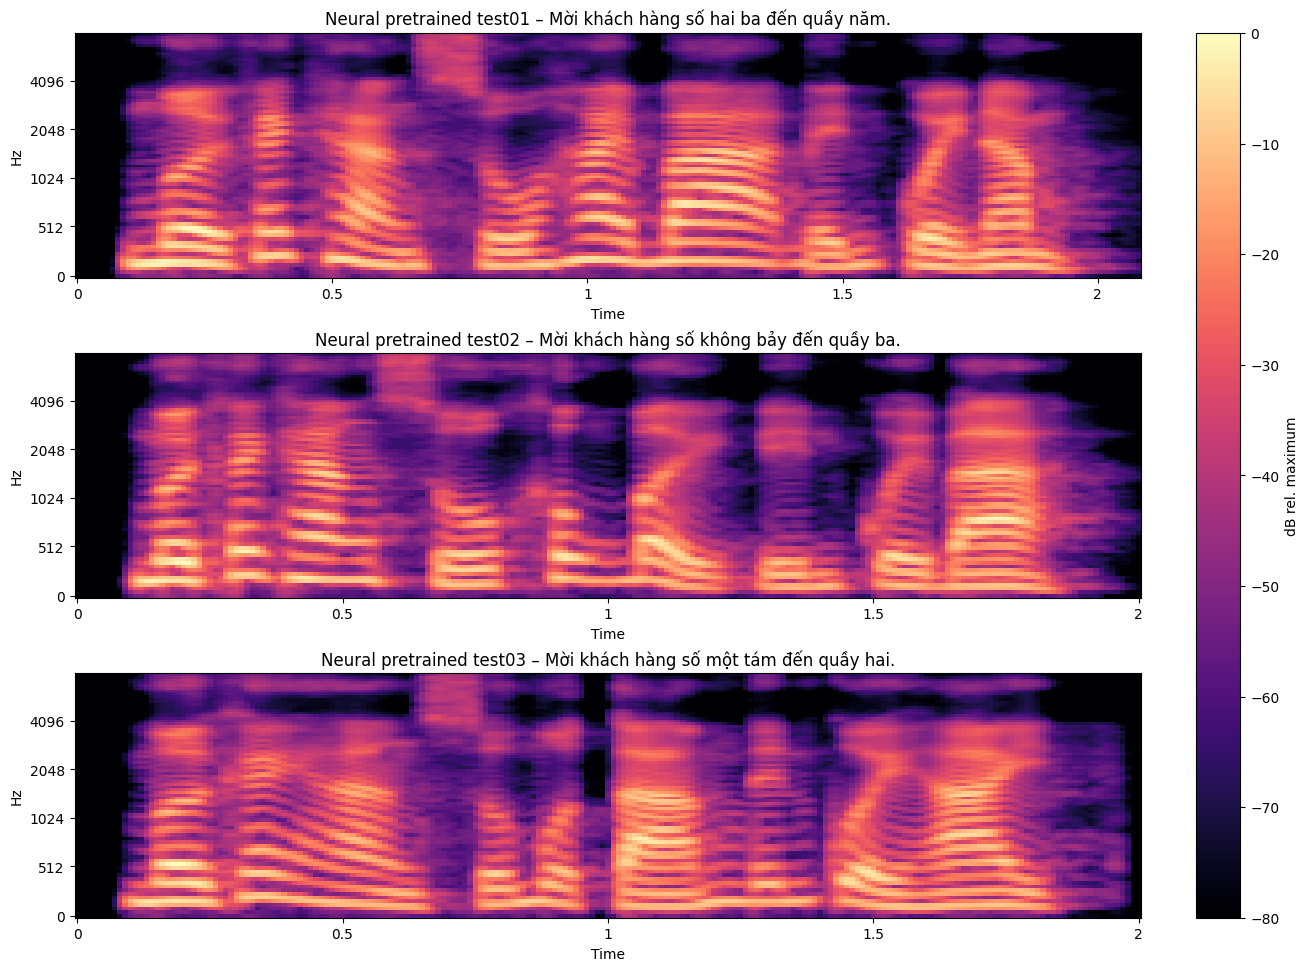

In [9]:
fig,axes=plt.subplots(len(METRICS_DF),1,figsize=(13,3.2*len(METRICS_DF)),layout='constrained')
if len(METRICS_DF)==1: axes=[axes]
last=None
for ax,(_,row) in zip(axes,METRICS_DF.iterrows()):
    y,sr=sf.read(row['audio_path_16k'],dtype='float32')
    mel=librosa.feature.melspectrogram(y=y,sr=sr,n_mels=80,
                                       n_fft=1024,hop_length=160)
    mel_db=librosa.power_to_db(mel,ref=np.max)
    last=librosa.display.specshow(mel_db,x_axis='time',y_axis='mel',
                     sr=sr,hop_length=160,ax=ax,cmap='magma',vmin=-80,vmax=0)
    ax.set_title(f"Neural pretrained {row['id']} – {row['spoken_text']}")
fig.colorbar(last,ax=axes,label='dB rel. maximum')
fig.savefig(FIG_DIR/'f_neural_mel_3tests.png',dpi=160,bbox_inches='tight')
plt.show()

## 7. So sánh tín hiệu neural và concatenation cho câu thứ nhất

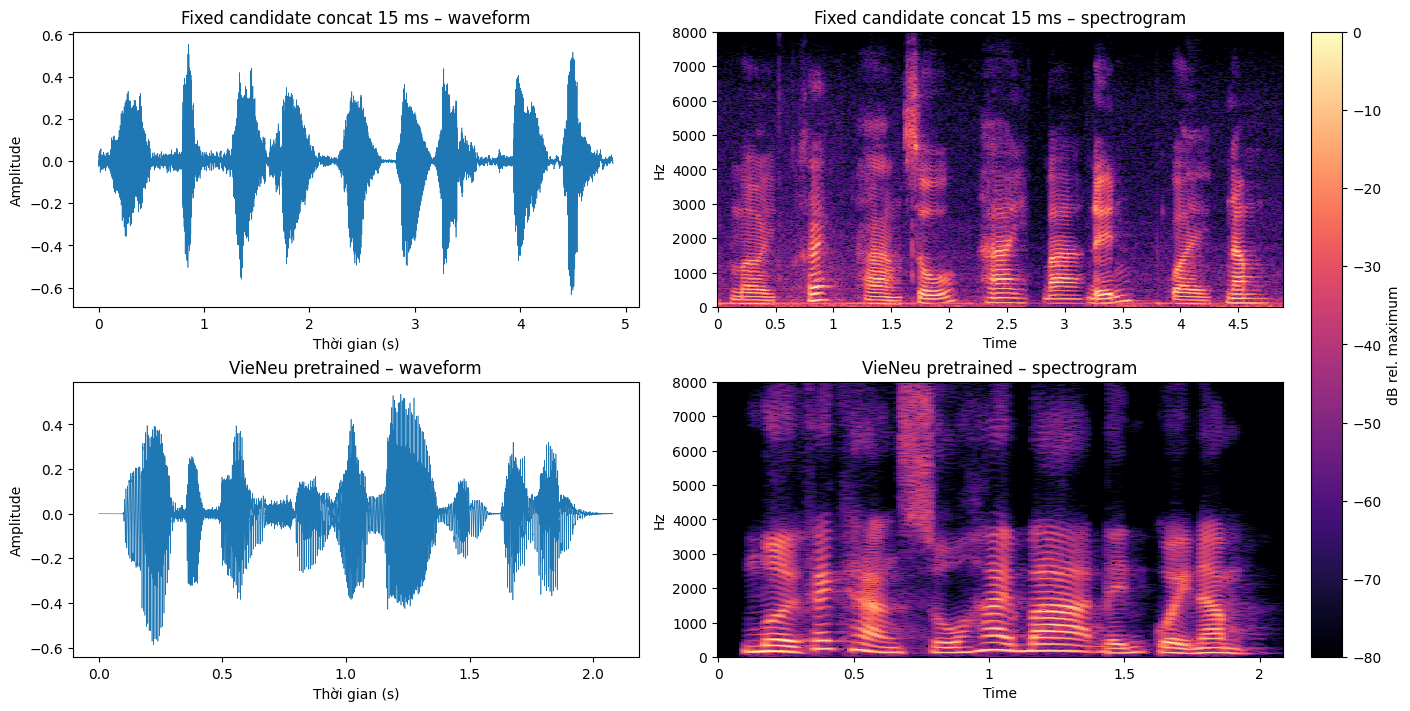

In [10]:
row=METRICS_DF.iloc[0]
fig,axes=plt.subplots(2,2,figsize=(14,7),layout='constrained')
for i,(method,p) in enumerate([('Fixed candidate concat 15 ms',row['concat_audio_path']),
                                 ('VieNeu pretrained',row['audio_path_16k'])]):
    y,sr=sf.read(p,dtype='float32')
    time_axis=np.arange(len(y))/sr
    axes[i,0].plot(time_axis,y,lw=.45)
    axes[i,0].set(title=f'{method} – waveform',xlabel='Thời gian (s)',ylabel='Amplitude')
    s=librosa.stft(y,n_fft=1024,hop_length=160)
    sdb=librosa.amplitude_to_db(np.abs(s),ref=np.max)
    im=librosa.display.specshow(sdb,sr=sr,hop_length=160,x_axis='time',y_axis='linear',
                                ax=axes[i,1],vmin=-80,vmax=0,cmap='magma')
    axes[i,1].set(title=f'{method} – spectrogram',ylim=(0,8000))
fig.colorbar(im,ax=[axes[0,1],axes[1,1]],label='dB rel. maximum')
fig.savefig(FIG_DIR/'f_neural_vs_concat_test01.png',dpi=150,bbox_inches='tight')
plt.show()

## 8. Đo và vẽ latency / RTF trên cùng máy

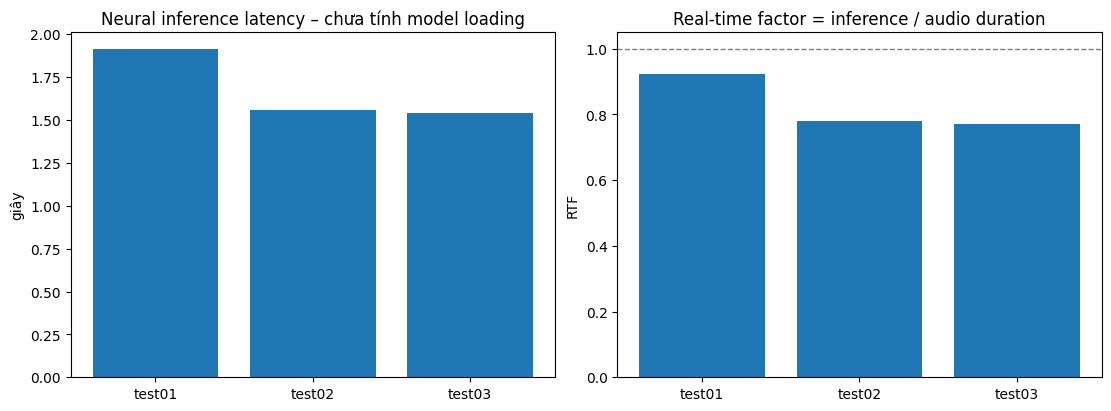

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].bar(METRICS_DF['id'],METRICS_DF['latency_s'])
axes[0].set(title='Neural inference latency – chưa tính model loading',ylabel='giây')
axes[1].bar(METRICS_DF['id'],METRICS_DF['RTF'])
axes[1].axhline(1,color='gray',lw=1,ls='--')
axes[1].set(title='Real-time factor = inference / audio duration',ylabel='RTF')
fig.savefig(FIG_DIR/'f_neural_latency_rtf.png',dpi=160,bbox_inches='tight')
plt.show()

## 9. Nghe mù và phiếu đánh giá (không điền điểm thay người nghe)

Nghe hai audio test 1 có thể hỗ trợ nhận xét. Dữ liệu listening test do người nghe thực sự chấm, không suy đoán MOS từ waveform. Trong báo cáo chỉ so sánh Neural TTS với HMM ở **tham số/giới hạn hệ thống**, không ghi MOS của HMM nếu HMM chưa sinh audio.

In [12]:
row=METRICS_DF.iloc[0]
print('Audio A – concatenation 15 ms')
display(Audio(filename=row['concat_audio_path']))
print('Audio B – neural pretrained (downsample 16k for comparison)')
display(Audio(filename=row['audio_path_16k']))

rating_path=EVAL_DIR/'f_listening_test_blank.csv'
if not rating_path.exists():
    blank=[]
    for t in TESTS:
        for method in ('concat','neural'):
            blank.append({'listener_id':'','test_id':t['id'],
                          'method':method,'naturalness_1to5':'',
                          'intelligibility_1to5':'','continuity_1to5':'',
                          'notes':''})
    pd.DataFrame(blank).to_csv(rating_path,index=False,encoding='utf-8-sig')
print('Phiếu đánh giá chưa chấm:',rating_path)
print('Không tính MOS hoặc intelligibility (%) khi chưa có kết quả người nghe.')

Audio A – concatenation 15 ms


Audio B – neural pretrained (downsample 16k for comparison)


Phiếu đánh giá chưa chấm: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\evaluation\f_listening_test_blank.csv
Không tính MOS hoặc intelligibility (%) khi chưa có kết quả người nghe.


## 10. Kết thúc F

- Kiểm tra 3 WAV bằng tai; kiểm tra số 23/07/18 có đọc đúng không.
- Ghi ảnh chụp Terminal và trạng thái mạng ngắt; chỉ dùng kết quả offline nếu thật sự chạy offline.
- Lưu `evaluation/f_neural_latency_comparison.csv`, hình trong `figures/` và 3 file WAV `audio_output/neural_testXX.wav`.
- Chuyển sang notebook `Lab04_Buoc7_G.ipynb` để so sánh ba phương pháp, tạo phiếu listening test và tổng hợp báo cáo.

**HMM** ở bước E mới tạo F0/spectral trajectory, chưa có vocoder nên không có waveform thật để chấm nghe/MOS cho HMM.